In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/yelp-dataset/yelp-dataset/Dataset_User_Agreement.pdf
/kaggle/input/datasets/yelp-dataset/yelp-dataset/yelp_academic_dataset_business.json
/kaggle/input/datasets/yelp-dataset/yelp-dataset/yelp_academic_dataset_checkin.json
/kaggle/input/datasets/yelp-dataset/yelp-dataset/yelp_academic_dataset_review.json
/kaggle/input/datasets/yelp-dataset/yelp-dataset/yelp_academic_dataset_tip.json
/kaggle/input/datasets/yelp-dataset/yelp-dataset/yelp_academic_dataset_user.json


## 1. Thiết lập môi trường & Kéo mã nguồn dự án

Cell code ngay bên dưới thực hiện clone (hoặc pull cập nhật) repository `toan58936/topic` về `/kaggle/working/topic`, thêm đường dẫn vào `sys.path` để import các module trong `src/` (`data_setup`, `baseline`, `metrics`, ...), và chuyển thư mục làm việc hiện tại sang thư mục repo.

In [3]:
import os, sys

GITHUB_TOKEN = ""  # Điền token GitHub nếu repo là Private, để trống nếu Public
REPO_URL = (
    f"https://{GITHUB_TOKEN}@github.com/toan58936/topic.git"
    if GITHUB_TOKEN
    else "https://github.com/toan58936/topic.git"
)
REPO_DIR = "/kaggle/working/topic"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
os.chdir(REPO_DIR)
print("Thư mục hiện tại:", os.getcwd())

Cloning into '/kaggle/working/topic'...
remote: Enumerating objects: 358, done.
remote: Counting objects: 100% (358/358), done.
remote: Compressing objects: 100% (252/252), done.
remote: Total 358 (delta 183), reused 262 (delta 103), pack-reused 0 (from 0)
Receiving objects: 100% (358/358), 366.75 KiB | 2.60 MiB/s, done.
Resolving deltas: 100% (183/183), done.
Thư mục hiện tại: /kaggle/working/topic


## 2. Chia dữ liệu Train / Val / Test (`prepare_splits`)

Cell code ngay bên dưới đọc dữ liệu review Yelp gốc, chuẩn hóa và loại bỏ trùng lặp theo quy tắc cấu hình, sau đó chia ngẫu nhiên có tái lập (`seed=42`) thành `42,000` Train / `9,001` Val / `8,999` Test (`Split ID: f0e6776f8a1a`) và lưu các file `.parquet` cùng `split_stats.json` vào `/kaggle/working/data`.

In [17]:
import json as _json
import shutil as _shutil
from pathlib import Path as _Path
from src.data_setup import prepare_splits

DATA_DIR = "/kaggle/working/data"
FORCE_RESPLIT = False  # Đổi thành True nếu muốn ép chia lại dữ liệu từ đầu

required_data_files = ["train.parquet", "val.parquet", "test.parquet", "split_stats.json"]
data_path = _Path(DATA_DIR)
data_path.mkdir(parents=True, exist_ok=True)

def _has_all_data(folder: _Path) -> bool:
    return all((folder / f).exists() for f in required_data_files)

# Nếu /kaggle/working/data chưa có, thử tìm từ Output cũ đã gắn trong /kaggle/input
if not FORCE_RESPLIT and not _has_all_data(data_path):
    for root, _, files in os.walk("/kaggle/input"):
        root_p = _Path(root)
        if _has_all_data(root_p):
            for fname in required_data_files + ["split_id.json"]:
                src_f = root_p / fname
                if src_f.exists():
                    _shutil.copy2(src_f, data_path / fname)
            print(f"📦 Đã khôi phục dữ liệu chia sẵn từ Input: {root_p}")
            break

if not FORCE_RESPLIT and _has_all_data(data_path):
    with open(data_path / "split_stats.json", "r", encoding="utf-8") as f:
        stats = _json.load(f)
    print("⏭️ Bỏ qua bước chia dữ liệu (đã có checkpoint hợp lệ).")
else:
    RAW_JSON = None
    for dirname, _, filenames in os.walk("/kaggle/input"):
        for fname in filenames:
            if fname in ("review.json", "yelp_academic_dataset_review.json") or fname.endswith("_review.json"):
                RAW_JSON = os.path.join(dirname, fname)
                break
        if RAW_JSON:
            break
    if RAW_JSON is None:
        raise FileNotFoundError("Không tìm thấy file review JSON trong /kaggle/input.")

    stats = prepare_splits(
        review_path=RAW_JSON,
        output_dir=DATA_DIR,
        n_samples=60000,
        ratios=(0.70, 0.15, 0.15),
        seed=42,
        overwrite=True,
    )
    print("🆕 Đã chia mới dữ liệu thành công.")

print("Split ID:", stats["split_id"])
print("Số lượng mẫu (Train / Val / Test):", stats["train_size"], stats["val_size"], stats["test_size"])

# Đảm bảo luôn có split_id.json
split_id_path = data_path / "split_id.json"
if not split_id_path.exists():
    with open(split_id_path, "w", encoding="utf-8") as f:
        _json.dump({"split_id": stats["split_id"]}, f, ensure_ascii=False, indent=2)

⏭️ Bỏ qua bước chia dữ liệu (đã có checkpoint hợp lệ).
Split ID: f0e6776f8a1a
Số lượng mẫu (Train / Val / Test): 42000 9001 8999


## 3. Khám phá dữ liệu (EDA) trên các tập Train / Val / Test

Các cell code tiếp theo phân tích dữ liệu đã chia tại `/kaggle/working/data` (`train.parquet`, `val.parquet`, `test.parquet` và `split_stats.json`) nhằm đánh giá:
* Phân phối nhãn `stars` (`1`–`5`) và mức độ đồng đều giữa các tập
* Độ dài văn bản (ký tự, từ) và tỷ lệ review vượt ngưỡng `256` token của Transformer
* Mối liên hệ giữa độ dài review và điểm sao `stars`
* Độ sạch, trùng lặp nội dung/định danh và mức độ lặp của `user_id` / `business_id`
* Các từ và cụm 2 từ (`1-gram`, `2-gram`) đặc trưng theo từng mức sao

In [5]:
import json
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

DATA_DIR = "/kaggle/working/data"

train_df = pd.read_parquet(f"{DATA_DIR}/train.parquet")
val_df = pd.read_parquet(f"{DATA_DIR}/val.parquet")
test_df = pd.read_parquet(f"{DATA_DIR}/test.parquet")

with open(f"{DATA_DIR}/split_stats.json", "r", encoding="utf-8") as f:
    split_stats = json.load(f)

splits = {"train": train_df, "val": val_df, "test": test_df}
star_levels = [1, 2, 3, 4, 5]

# 1. Tinh max_diff cho cell eda-stars-cell
counts = pd.DataFrame({
    name: df["stars"].astype(int).value_counts().reindex(star_levels, fill_value=0)
    for name, df in splits.items()
})
pcts = counts.div(counts.sum(axis=0), axis=1).mul(100).round(2)
max_diff = {
    f"star_{k}": round(float(pcts.loc[k].max() - pcts.loc[k].min()), 2)
    for k in star_levels
}

# 2. Tinh full_df, grp_summary va he so tuong quan cho cell eda-bystar-cell
full_df = pd.concat(
    [df.assign(split=name) for name, df in splits.items()],
    ignore_index=True,
)
full_df["stars_int"] = full_df["stars"].astype(int)
full_df["word_len"] = [len(t.split()) for t in full_df["text"].astype(str)]
full_df["char_len"] = full_df["text"].astype(str).str.len()

def _group_label(s: int) -> str:
    if s <= 2:
        return "Che (1-2 sao)"
    if s == 3:
        return "Trung lap (3 sao)"
    return "Khen (4-5 sao)"

full_df["sentiment_group"] = full_df["stars_int"].map(_group_label)
grp_summary = (
    full_df.groupby("sentiment_group")
    .agg(word_mean=("word_len", "mean"), word_median=("word_len", "median"))
    .round(2)
)

pearson_w = float(full_df["word_len"].corr(full_df["stars"], method="pearson"))
spearman_w = float(full_df["word_len"].corr(full_df["stars"], method="spearman"))
pearson_c = float(full_df["char_len"].corr(full_df["stars"], method="pearson"))
spearman_c = float(full_df["char_len"].corr(full_df["stars"], method="spearman"))

# 3. Tinh norm_sets va id_summary_rows cho cell eda-quality-cell
norm_sets = {}
for name, df in splits.items():
    norm_text = df["text"].astype(str).str.lower().str.strip().str.replace(r"\s+", " ", regex=True)
    norm_sets[name] = set(norm_text)

id_summary_rows = []
for id_col in ["user_id", "business_id"]:
    vc = full_df[id_col].astype(str).value_counts()
    n_total = len(full_df)
    n_unique = len(vc)
    n_gt1 = int((vc > 1).sum())
    rows_in_gt1 = int(vc[vc > 1].sum())
    id_summary_rows.append({
        "id_col": id_col,
        "reviews_per_id_mean": round(float(vc.mean()), 2),
        "pct_ids_with_gt1": round(float(n_gt1 / n_unique * 100), 2),
        "pct_reviews_from_gt1_ids": round(float(rows_in_gt1 / n_total * 100), 2),
    })

# 4. Tinh ma tran TF-IDF cho cell eda-ngram-cell
vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.95,
    sublinear_tf=True,
    lowercase=True,
)
X_tfidf = vectorizer.fit_transform(train_df["text"].astype(str))
vocab = np.array(vectorizer.get_feature_names_out())
stars = train_df["stars"].to_numpy(dtype=int)

print("✅ Da chuan bi xong toan bo du lieu va bien thong ke cho cac bieu do EDA!")


✅ Da chuan bi xong toan bo du lieu va bien thong ke cho cac bieu do EDA!


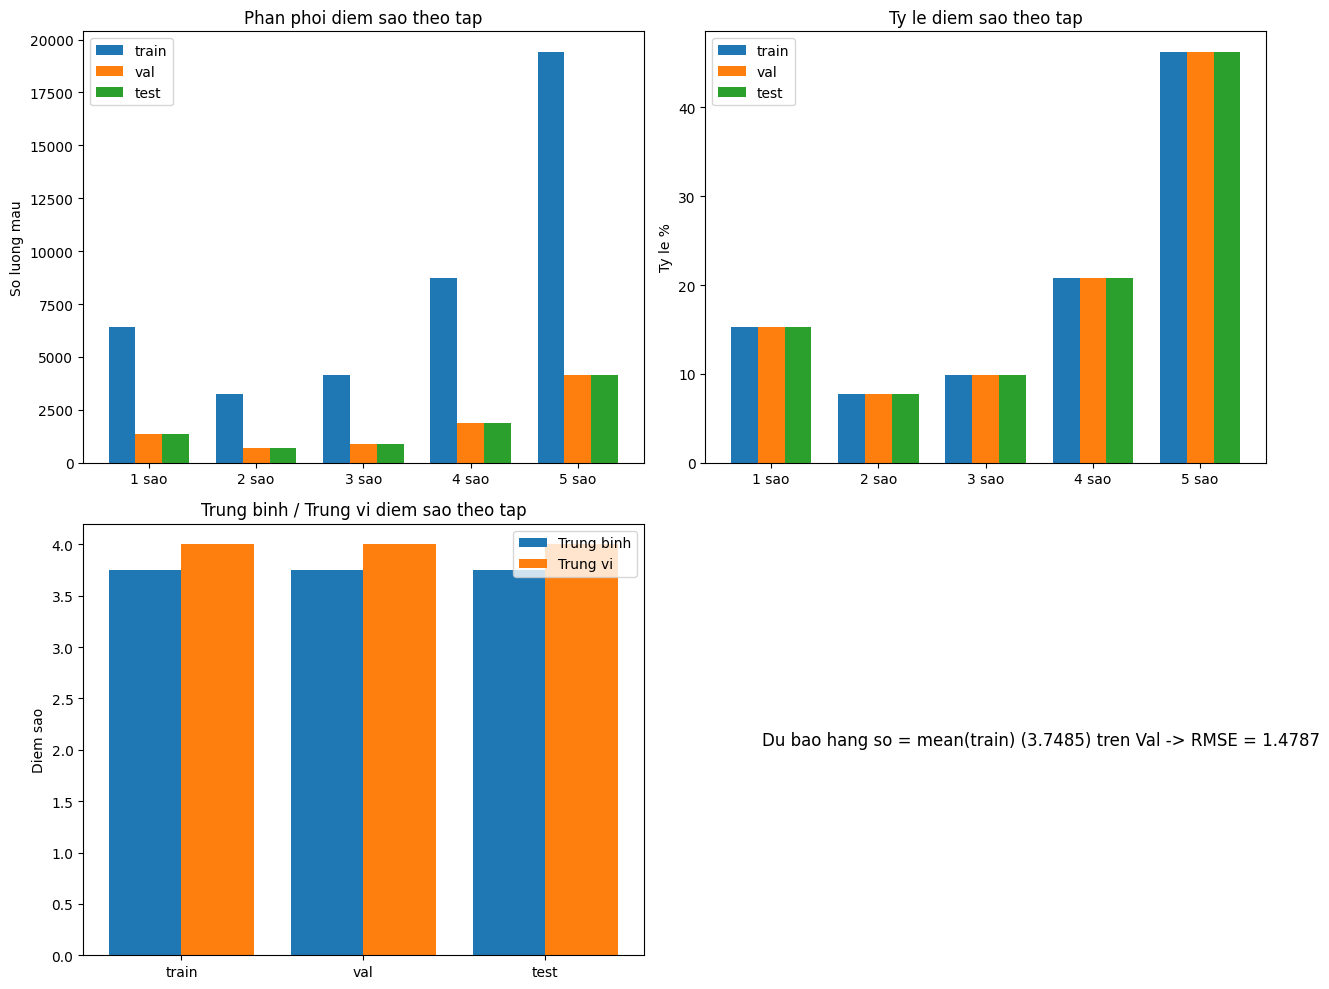

Split ID: f0e6776f8a1a
Do lech ty le (%) lon nhat giua cac tap: {'star_1': 0.0, 'star_2': 0.01, 'star_3': 0.0, 'star_4': 0.01, 'star_5': 0.01}


In [6]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.figsize'] = (14, 10)

fig, axes = plt.subplots(2, 2)

# 1. Grouped bar: so luong sao theo tap
ax = axes[0, 0]
x = np.arange(5)
width = 0.25
for i, (name, df) in enumerate(splits.items()):
    counts = df['stars'].value_counts().reindex([1,2,3,4,5], fill_value=0)
    ax.bar(x + i*width, counts.values, width, label=name)
ax.set_xticks(x + width)
ax.set_xticklabels(['1 sao', '2 sao', '3 sao', '4 sao', '5 sao'])
ax.set_ylabel('So luong mau')
ax.set_title('Phan phoi diem sao theo tap')
ax.legend()

# 2. Grouped bar: ty le % sao theo tap
ax = axes[0, 1]
for i, (name, df) in enumerate(splits.items()):
    counts = df['stars'].value_counts().reindex([1,2,3,4,5], fill_value=0)
    pcts = counts.values / len(df) * 100
    ax.bar(x + i*width, pcts, width, label=name)
ax.set_xticks(x + width)
ax.set_xticklabels(['1 sao', '2 sao', '3 sao', '4 sao', '5 sao'])
ax.set_ylabel('Ty le %')
ax.set_title('Ty le diem sao theo tap')
ax.legend()

# 3. Bar: trung binh / trung vi diem sao theo tap
ax = axes[1, 0]
tap_names = list(splits.keys())
means = [float(splits[n]['stars'].mean()) for n in tap_names]
medians = [float(splits[n]['stars'].median()) for n in tap_names]
ax.bar(np.arange(len(tap_names)) - 0.2, means, 0.4, label='Trung binh')
ax.bar(np.arange(len(tap_names)) + 0.2, medians, 0.4, label='Trung vi')
ax.set_xticks(np.arange(len(tap_names)))
ax.set_xticklabels(tap_names)
ax.set_ylabel('Diem sao')
ax.set_title('Trung binh / Trung vi diem sao theo tap')
ax.legend()

# 4. Text: RMSE du bao hang so
ax = axes[1, 1]
ax.axis('off')
train_mean = float(train_df['stars'].mean())
val_y = val_df['stars'].to_numpy(dtype=float)
rmse_mean = float(np.sqrt(np.mean((val_y - train_mean) ** 2)))
ax.text(0.1, 0.5, f'Du bao hang so = mean(train) ({train_mean:.4f}) tren Val -> RMSE = {rmse_mean:.4f}',
          fontsize=12, va='center')

plt.tight_layout()
plt.show()

print(f'Split ID: {split_stats.get("split_id")}')
print(f'Do lech ty le (%) lon nhat giua cac tap: {max_diff}')


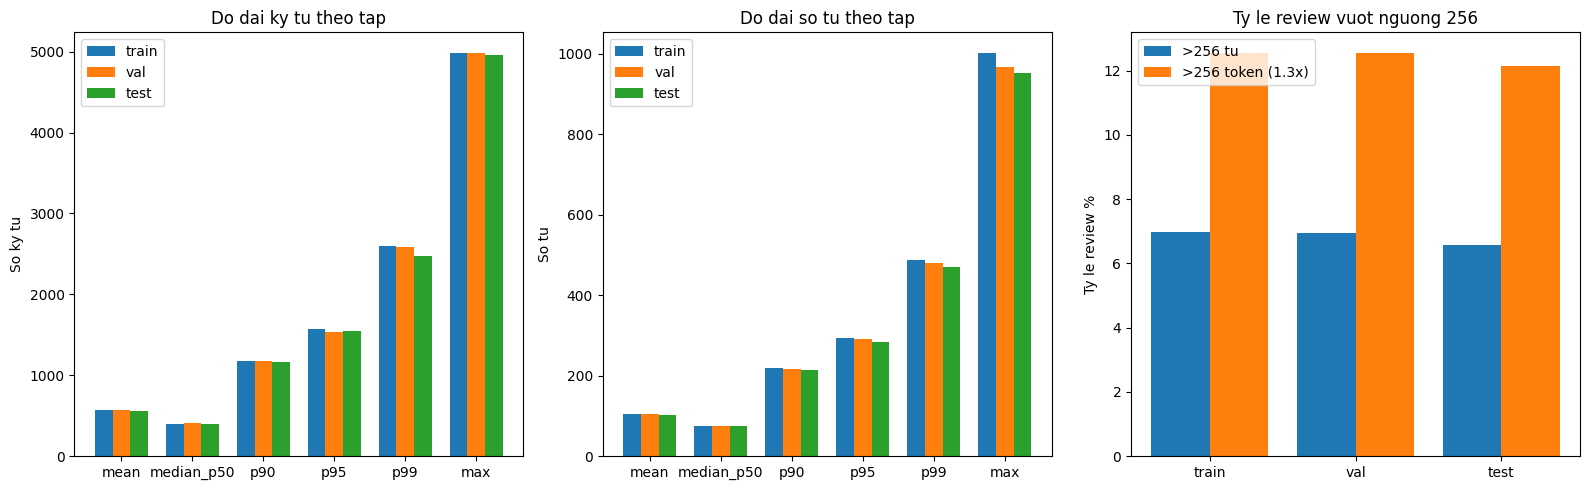

In [7]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Do dai ky tu theo tap
ax = axes[0]
metrics_c = ['mean', 'median_p50', 'p90', 'p95', 'p99', 'max']
x = np.arange(len(metrics_c))
width = 0.25
for i, (name, df) in enumerate(splits.items()):
    char_lens = df['text'].astype(str).str.len()
    vals = [float(char_lens.mean()), float(char_lens.quantile(0.50)),
            float(char_lens.quantile(0.90)), float(char_lens.quantile(0.95)),
            float(char_lens.quantile(0.99)), int(char_lens.max())]
    ax.bar(x + i*width, vals, width, label=name)
ax.set_xticks(x + width)
ax.set_xticklabels(metrics_c)
ax.set_ylabel('So ky tu')
ax.set_title('Do dai ky tu theo tap')
ax.legend()

# 2. Do dai so tu theo tap
ax = axes[1]
for i, (name, df) in enumerate(splits.items()):
    word_lens = pd.Series([len(t.split()) for t in df['text'].astype(str)], index=df.index)
    vals = [float(word_lens.mean()), float(word_lens.quantile(0.50)),
            float(word_lens.quantile(0.90)), float(word_lens.quantile(0.95)),
            float(word_lens.quantile(0.99)), int(word_lens.max())]
    ax.bar(x + i*width, vals, width, label=name)
ax.set_xticks(x + width)
ax.set_xticklabels(metrics_c)
ax.set_ylabel('So tu')
ax.set_title('Do dai so tu theo tap')
ax.legend()

# 3. Ty le review > 256 tu / token
ax = axes[2]
pct_words = []
pct_tokens = []
for name, df in splits.items():
    word_lens = pd.Series([len(t.split()) for t in df['text'].astype(str)], index=df.index)
    pct_words.append(float((word_lens > 256).mean() * 100))
    pct_tokens.append(float(((word_lens * 1.3) > 256).mean() * 100))
x = np.arange(len(splits))
ax.bar(x - 0.2, pct_words, 0.4, label='>256 tu')
ax.bar(x + 0.2, pct_tokens, 0.4, label='>256 token (1.3x)')
ax.set_xticks(x)
ax.set_xticklabels(list(splits.keys()))
ax.set_ylabel('Ty le review %')
ax.set_title('Ty le review vuot nguong 256')
ax.legend()

plt.tight_layout()
plt.show()


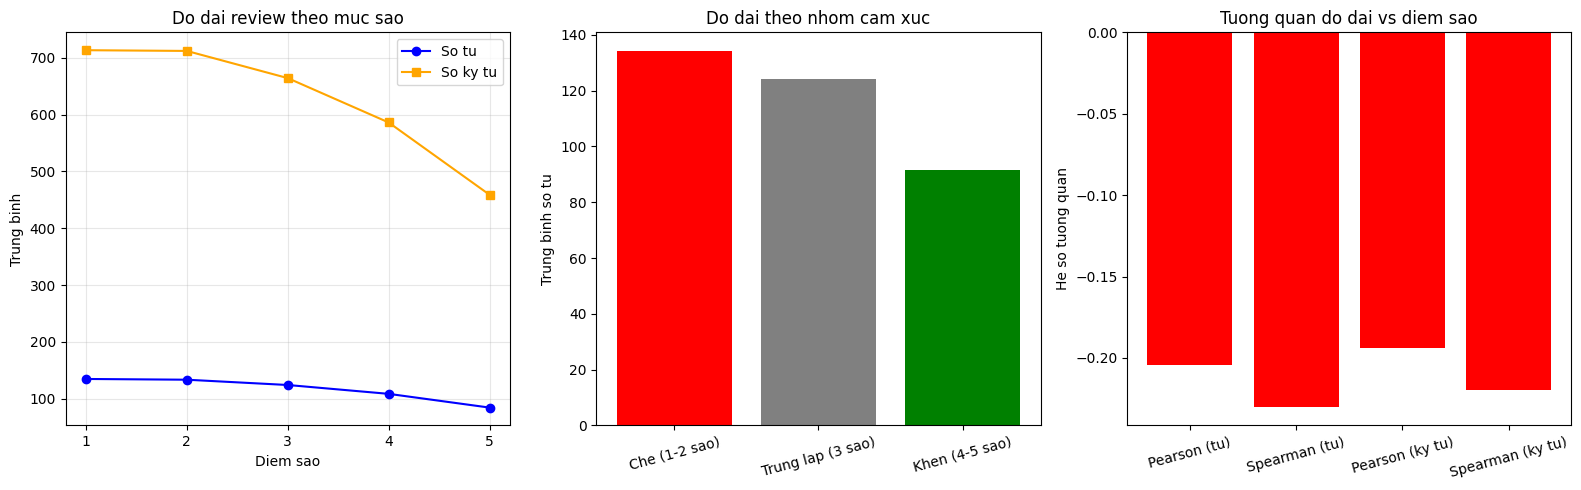

In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Duong: do dai trung binh theo muc sao
ax = axes[0]
star_means_word = []
star_means_char = []
for s in [1, 2, 3, 4, 5]:
    grp = full_df[full_df['stars_int'] == s]
    star_means_word.append(float(grp['word_len'].mean()))
    star_means_char.append(float(grp['char_len'].mean()))
ax.plot([1, 2, 3, 4, 5], star_means_word, marker='o', label='So tu', color='blue')
ax.plot([1, 2, 3, 4, 5], star_means_char, marker='s', label='So ky tu', color='orange')
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel('Diem sao')
ax.set_ylabel('Trung binh')
ax.set_title('Do dai review theo muc sao')
ax.legend()
ax.grid(True, alpha=0.3)

# 2. Bar: do dai theo nhom cam xuc
ax = axes[1]
groups = ['Che (1-2 sao)', 'Trung lap (3 sao)', 'Khen (4-5 sao)']
gmeans = [float(grp_summary.loc[g, 'word_mean']) for g in groups]
ax.bar(groups, gmeans, color=['red', 'gray', 'green'])
ax.set_ylabel('Trung binh so tu')
ax.set_title('Do dai theo nhom cam xuc')
ax.tick_params(axis='x', rotation=15)

# 3. Bar: he so tuong quan
ax = axes[2]
corr_names = ['Pearson (tu)', 'Spearman (tu)', 'Pearson (ky tu)', 'Spearman (ky tu)']
corr_vals = [pearson_w, spearman_w, pearson_c, spearman_c]
colors = ['green' if v > 0 else 'red' for v in corr_vals]
ax.bar(corr_names, corr_vals, color=colors)
ax.set_ylabel('He so tuong quan')
ax.set_title('Tuong quan do dai vs diem sao')
ax.tick_params(axis='x', rotation=15)
ax.axhline(0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()


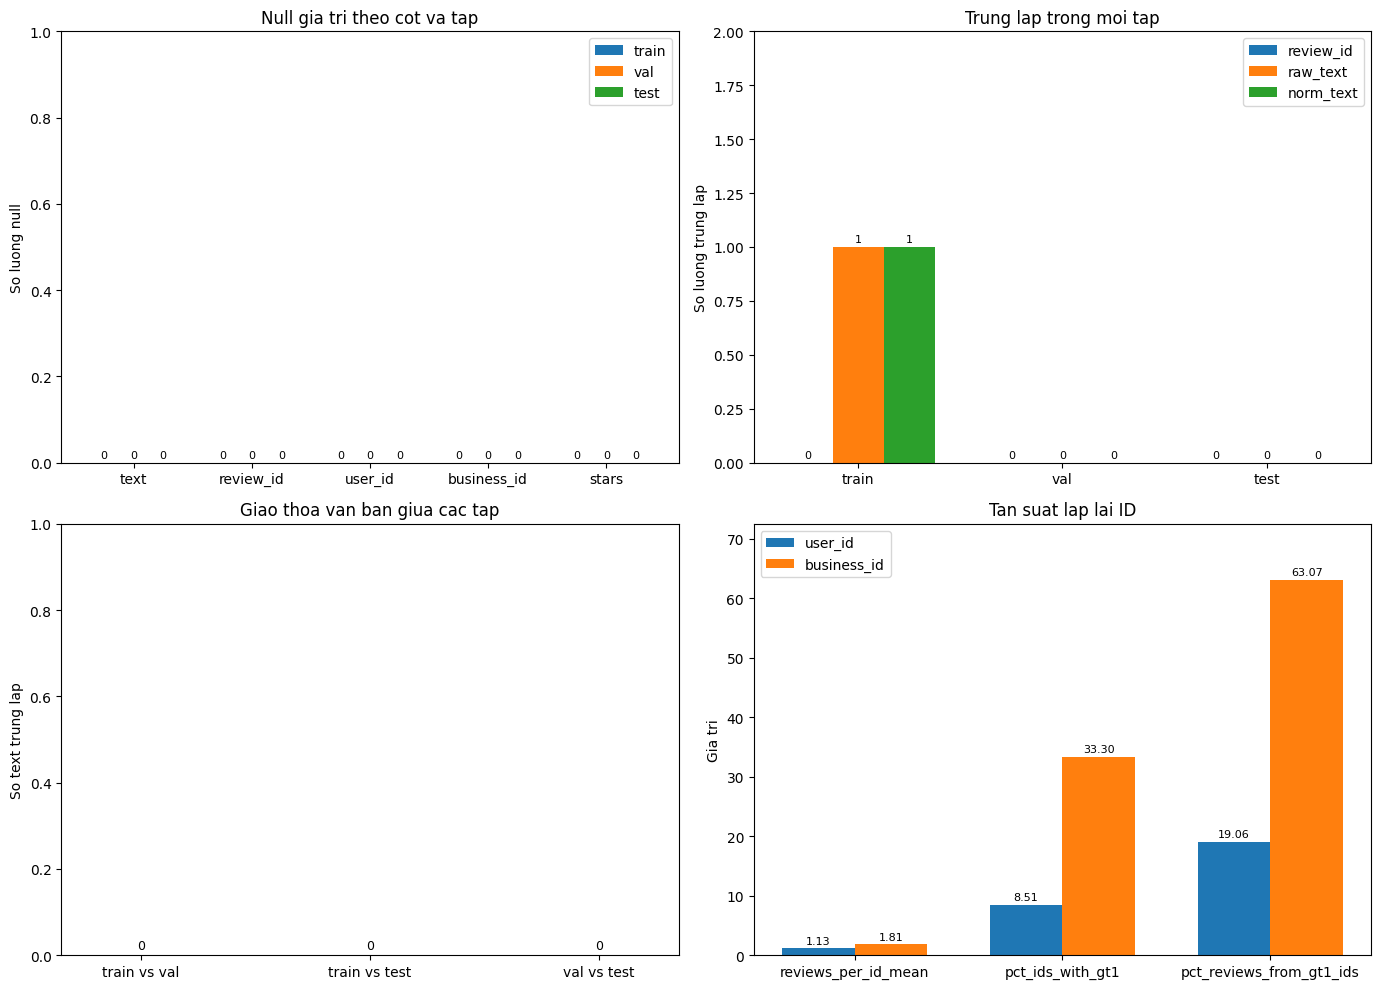

In [14]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Bar: null gia tri theo cot va tap
ax = axes[0, 0]
target_cols = ['text', 'review_id', 'user_id', 'business_id', 'stars']
col_nulls = {col: [] for col in target_cols}
for name, df in splits.items():
    for col in target_cols:
        col_nulls[col].append(int(df[col].isna().sum()))

x = np.arange(len(target_cols))
width = 0.25
for i, (name, _) in enumerate(splits.items()):
    vals = [col_nulls[col][i] for col in target_cols]
    bars = ax.bar(x + i * width, vals, width, label=name)
    ax.bar_label(bars, padding=2, fontsize=8)
ax.set_xticks(x + width)
ax.set_xticklabels(target_cols)
ax.set_ylim(0, max(1, max(max(v) for v in col_nulls.values()) + 1))
ax.set_ylabel('So luong null')
ax.set_title('Null gia tri theo cot va tap')
ax.legend()

# 2. Bar: trung lap trong tap
ax = axes[0, 1]
dup_categories = ['dup_review_id_in_split', 'dup_raw_text_in_split', 'dup_norm_text_in_split']
dup_vals = {cat: [] for cat in dup_categories}
for name, df in splits.items():
    rids = df['review_id'].astype(str)
    raw_text = df['text'].astype(str)
    norm_text = raw_text.str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
    dup_vals['dup_review_id_in_split'].append(int(rids.duplicated().sum()))
    dup_vals['dup_raw_text_in_split'].append(int(raw_text.duplicated().sum()))
    dup_vals['dup_norm_text_in_split'].append(int(norm_text.duplicated().sum()))

x = np.arange(len(splits))
width = 0.25
for i, cat in enumerate(dup_categories):
    bars = ax.bar(x + i * width, dup_vals[cat], width, label=cat.replace('dup_', '').replace('_in_split', ''))
    ax.bar_label(bars, padding=2, fontsize=8)
ax.set_xticks(x + width)
ax.set_xticklabels(list(splits.keys()))
ax.set_ylim(0, max(2, max(max(v) for v in dup_vals.values()) + 0.5))
ax.set_ylabel('So luong trung lap')
ax.set_title('Trung lap trong moi tap')
ax.legend()

# 3. Bar: giao thoa giua cac tap
ax = axes[1, 0]
pairs = [('train', 'val'), ('train', 'test'), ('val', 'test')]
overlaps = [len(norm_sets[a] & norm_sets[b]) for a, b in pairs]
bars = ax.bar([f'{a} vs {b}' for a, b in pairs], overlaps, color='purple', width=0.45)
ax.bar_label(bars, padding=2, fontsize=9)
ax.set_ylim(0, max(1, max(overlaps) + 1))
ax.set_ylabel('So text trung lap')
ax.set_title('Giao thoa van ban giua cac tap')

# 4. Bar: tan suat lap lai ID
ax = axes[1, 1]
id_metrics = ['reviews_per_id_mean', 'pct_ids_with_gt1', 'pct_reviews_from_gt1_ids']
x = np.arange(len(id_metrics))
width = 0.35
user_vals = [id_summary_rows[0][m] for m in id_metrics]
biz_vals = [id_summary_rows[1][m] for m in id_metrics]
b1 = ax.bar(x - width / 2, user_vals, width, label='user_id')
b2 = ax.bar(x + width / 2, biz_vals, width, label='business_id')
ax.bar_label(b1, fmt='%.2f', padding=2, fontsize=8)
ax.bar_label(b2, fmt='%.2f', padding=2, fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(id_metrics)
ax.set_ylim(0, max(biz_vals) * 1.15)
ax.set_ylabel('Gia tri')
ax.set_title('Tan suat lap lai ID')
ax.legend()

plt.tight_layout()
plt.show()

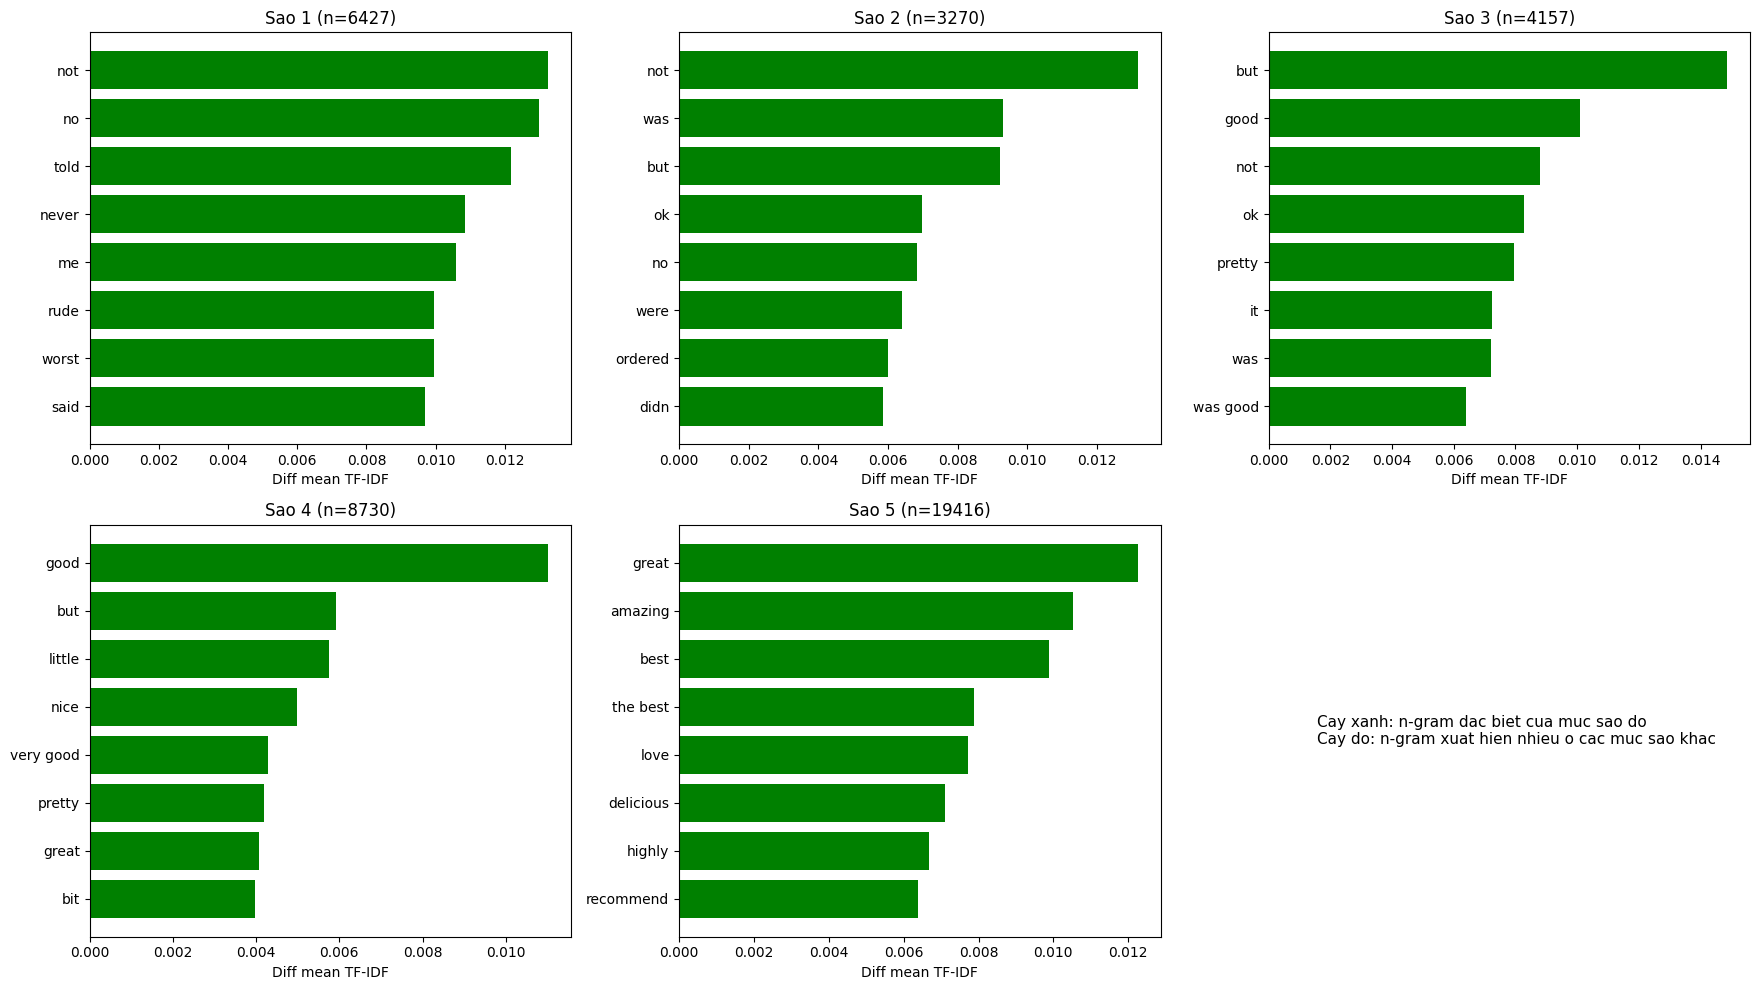

In [10]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx, s in enumerate([1, 2, 3, 4, 5]):
    ax = axes[idx]
    mask_s = stars == s
    mask_other = ~mask_s
    mean_s = np.asarray(X_tfidf[mask_s].mean(axis=0)).ravel()
    mean_other = np.asarray(X_tfidf[mask_other].mean(axis=0)).ravel()
    diff_score = mean_s - mean_other
    top_idx = np.argsort(diff_score)[::-1][:8]
    terms = [vocab[i] for i in top_idx]
    vals = [diff_score[i] for i in top_idx]
    colors = ['green' if v > 0 else 'red' for v in vals]
    ax.barh(range(len(terms)), vals, color=colors)
    ax.set_yticks(range(len(terms)))
    ax.set_yticklabels(terms)
    ax.invert_yaxis()
    ax.set_title(f'Sao {s} (n={int(mask_s.sum())})')
    ax.set_xlabel('Diff mean TF-IDF')

axes[5].axis('off')
axes[5].text(0.1, 0.5, 'Cay xanh: n-gram dac biet cua muc sao do\nCay do: n-gram xuat hien nhieu o cac muc sao khac',
              fontsize=11, va='center')

plt.tight_layout()
plt.show()


## 4. Mo hinh co so Baseline (`TF-IDF + Ridge`)

Huuan luyen va tim kiem luoi `84` to hop siêu tham so tren tap `Train`, chon mo hien tot nhat theo RMSE Val.


In [11]:
from pathlib import Path
import shutil
import joblib
import pickle
import pandas as pd
from src.baseline import fit_baseline, predict_baseline, save_baseline
from src.metrics import compute_metrics, per_star_metrics, threshold_moc1, mean_predictor_metrics

DATA_DIR = "/kaggle/working/data"
PREDS_DIR = Path("/kaggle/working/results/preds")
PREDS_DIR.mkdir(parents=True, exist_ok=True)
FORCE_RETRAIN_BASELINE = False  # Đổi thành True nếu muốn chạy lại Grid Search 84 tổ hợp

train_df = pd.read_parquet(f"{DATA_DIR}/train.parquet")
val_df   = pd.read_parquet(f"{DATA_DIR}/val.parquet")
test_df  = pd.read_parquet(f"{DATA_DIR}/test.parquet")

# 1. Mốc dự đoán trung bình (tính rất nhanh < 0.01s)
mean_m = mean_predictor_metrics(train_df["stars"], float(train_df["stars"].mean()))
print(f"Mean Predictor Val RMSE: {mean_m['rmse']:.4f} | MAE: {mean_m['mae']:.4f}")

pkl_path = PREDS_DIR / "baseline_val.pkl"
csv_path = PREDS_DIR / "baseline_test.csv"

# Nếu chưa có trong /kaggle/working, tìm từ Output cũ trong /kaggle/input
if not FORCE_RETRAIN_BASELINE and not (pkl_path.exists() and csv_path.exists()):
    for root, _, files in os.walk("/kaggle/input"):
        root_p = Path(root)
        if (root_p / "baseline_val.pkl").exists() and (root_p / "baseline_test.csv").exists():
            shutil.copy2(root_p / "baseline_val.pkl", pkl_path)
            shutil.copy2(root_p / "baseline_test.csv", csv_path)
            print(f"📦 Đã khôi phục checkpoint Baseline từ Input: {root_p}")
            break

# 2. Tải checkpoint hoặc huấn luyện mới
if not FORCE_RETRAIN_BASELINE and pkl_path.exists() and csv_path.exists():
    try:
        res = joblib.load(pkl_path)
    except Exception:
        with open(pkl_path, "rb") as f:
            res = pickle.load(f)
    print("⏭️ Bỏ qua Grid Search Baseline (đã tải checkpoint baseline_val.pkl).")
else:
    res = fit_baseline(train_df, val_df, seed=42)
    save_baseline(res, pkl_path, overwrite=True)

    test_pred = predict_baseline(res["pipeline"], test_df["text"].tolist())
    pd.DataFrame({
        "review_id": test_df["review_id"],
        "true_stars": test_df["stars"].to_numpy(dtype=int),
        "pred_baseline": test_pred
    }).to_csv(csv_path, index=False)
    print("🆕 Đã train xong và lưu mới baseline_val.pkl & baseline_test.csv!")

val_pred = predict_baseline(res["pipeline"], val_df["text"].tolist())
val_m = compute_metrics(val_df["stars"], val_pred)
val_ps = per_star_metrics(val_df["stars"], val_pred)

print("Best params:", res["best_params"])
print(f"Baseline Val RMSE: {val_m['rmse']:.4f} | MAE: {val_m['mae']:.4f} | Macro-MAE: {val_ps['macro_mae']:.4f}")
print(f"Ngưỡng mục tiêu Mốc 1 (0.85 * RMSE_val): {threshold_moc1(val_m['rmse']):.4f}")

Mean Predictor Val RMSE: 1.4787 | MAE: 1.2616
Best params: {'max_features': np.int64(20000), 'ngram_range': (1, 2), 'min_df': np.int64(5), 'alpha': np.float64(1.0)}
Baseline Val RMSE: 0.7792 | MAE: 0.5758 | Macro-MAE: 0.6329
Ngưỡng mục tiêu Mốc 1 (0.85 * RMSE_val): 0.6623
Đã lưu xong baseline_val.pkl và baseline_test.csv!


In [12]:
import os
from pathlib import Path

# Danh sach file output san sang tai xuong tu Kaggle
for d in ['/kaggle/working/data', '/kaggle/working/results/preds']:
    p = Path(d)
    print(f'\n=== {d} ===')
    if p.exists():
        for f in sorted(p.iterdir()):
            size = f.stat().st_size / 1024 / 1024
            print(f'  {f.name}  ({size:.2f} MB)')
    else:
        print('  (chua co thu muc)')

print('\nTai cac file tren qua Output panel cua Kaggle (blue download icon).')
print('Sau do upload len Google Drive: My Drive/topic/{data, results/preds}')



=== /kaggle/working/data ===
  split_id.json  (0.00 MB)
  split_stats.json  (0.00 MB)
  test.parquet  (3.59 MB)
  train.parquet  (16.75 MB)
  val.parquet  (3.64 MB)

=== /kaggle/working/results/preds ===
  baseline_test.csv  (0.35 MB)
  baseline_val.pkl  (0.89 MB)

Tai cac file tren qua Output panel cua Kaggle (blue download icon).
Sau do upload len Google Drive: My Drive/topic/{data, results/preds}
